# 02 · Limpieza, filtrado y transformación
El pipeline vive en `src/ypf_ds/data/clean.py` (reproducible e idempotente, corre en ~2 s con Polars). Acá lo ejecutamos y verificamos cada regla.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

In [2]:
from ypf_ds.data import clean
from ypf_ds.data.load import escanear_crudo
antes = escanear_crudo().collect()
panel, pozos = clean.construir()
print(f"Crudo: {antes.shape} → Panel Neuquina: {panel.shape} | Pozos: {pozos.height}")

Crudo: (421046, 24) → Panel Neuquina: (382992, 13) | Pozos: 4682


## Reglas aplicadas
| Paso | Regla |
|---|---|
| Filtro | `cuenca == NEUQUINA`, sin inyectores/sumideros/acuíferos ni pozos de servicio |
| Columnas | se descartan `vida_util`, `observaciones`, `iny_*`, metadata de carga |
| Negativos | producción < 0 → 0 |
| `tef` | acotado a [0, días del mes]; si hay producción con `tef = 0` → mes completo |
| Profundidad | fuera de [300, 8000] m → mediana del pozo → mediana (formación, yacimiento) → formación |
| Coordenadas | longitud > -60 → lat/lon invertidas, se intercambian |
| Operadora | última informada (981 pozos cambiaron de operadora) |
| Grilla | todos los meses desde el primer mes productivo; faltantes = 0 con `mes_faltante = True` |
| Fluido | `petroleo` si GOR acumulado < 3.000 m³/m³, si no `gas` |

In [3]:
verif = pl.DataFrame({
    "chequeo": ["negativos", "tef > días del mes", "duplicados pozo-mes", "profundidad nula", "coord. invertidas"],
    "antes": [int((antes.filter(pl.col("cuenca")=="NEUQUINA")["prod_gas"] < 0).sum()),
              int((antes["tef"] > 31).sum()),
              antes.height - antes.unique(["idpozo","anio","mes"]).height,
              int(((antes["profundidad"] == 0) | (antes["profundidad"] > 8000)).sum()),
              int((antes["coordenadax"] > -60).sum())],
    "despues": [int((panel["prod_gas"] < 0).sum()), int((panel["tef"] > panel["dias_mes"]).sum()),
                panel.height - panel.unique(["idpozo","fecha"]).height,
                int(pozos["profundidad"].null_count()), int((pozos["lon"] > -60).sum())]})
verif

chequeo,antes,despues
str,i64,i64
"""negativos""",2,0
"""tef > días del mes""",15,0
"""duplicados pozo-mes""",0,0
"""profundidad nula""",5890,0
"""coord. invertidas""",68,0


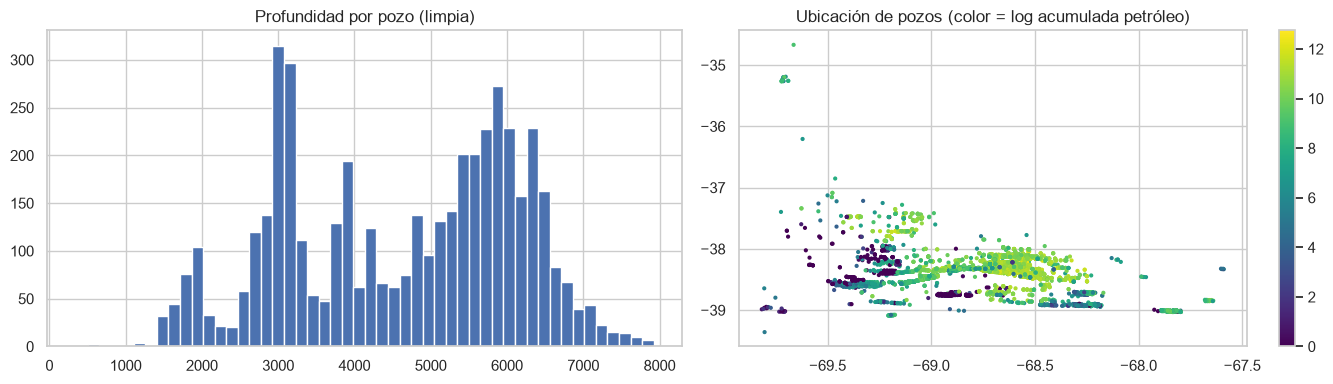

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(pozos["profundidad"], bins=50); ax[0].set_title("Profundidad por pozo (limpia)")
sc = ax[1].scatter(pozos["lon"], pozos["lat"], c=np.log1p(pozos["acum_pet"]), s=4, cmap="viridis")
ax[1].set_title("Ubicación de pozos (color = log acumulada petróleo)"); plt.colorbar(sc, ax=ax[1])
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_limpio.png", dpi=110); plt.show()

In [5]:
pozos.group_by("fluido").agg(pl.len().alias("pozos"), pl.col("acum_pet").sum().round(0), pl.col("acum_gas").sum().round(0))

fluido,pozos,acum_pet,acum_gas
str,u32,f64,f64
"""petroleo""",2708,1.30891769e8,3.0470075e7
"""gas""",1974,9.151419e6,2.24716632e8


## Complemento: padrón de pozos Capítulo IV (`capitulo-iv-pozos.csv`)
Padrón de 85.611 pozos de todo el país con cota, profundidad y **fechas de perforación y terminación**. Se une por `idpozo` y aporta datos conocidos *antes* de que el pozo produzca:
- `dias_perf`: duración de la perforación. `dias_term`: duración de la terminación (proxy de la cantidad de etapas de fractura).
- `es_horizontal`: la sigla del pozo termina en `(h)` cuando es horizontal (dato de la tabla de producción).

Cobertura sobre los pozos de Neuquina:
shape: (1, 3)
┌─────────┬───────────┬───────────┐
│ cota    ┆ dias_perf ┆ dias_term │
│ ---     ┆ ---       ┆ ---       │
│ f64     ┆ f64       ┆ f64       │
╞═════════╪═══════════╪═══════════╡
│ 0.98334 ┆ 0.983127  ┆ 0.963691  │
└─────────┴───────────┴───────────┘


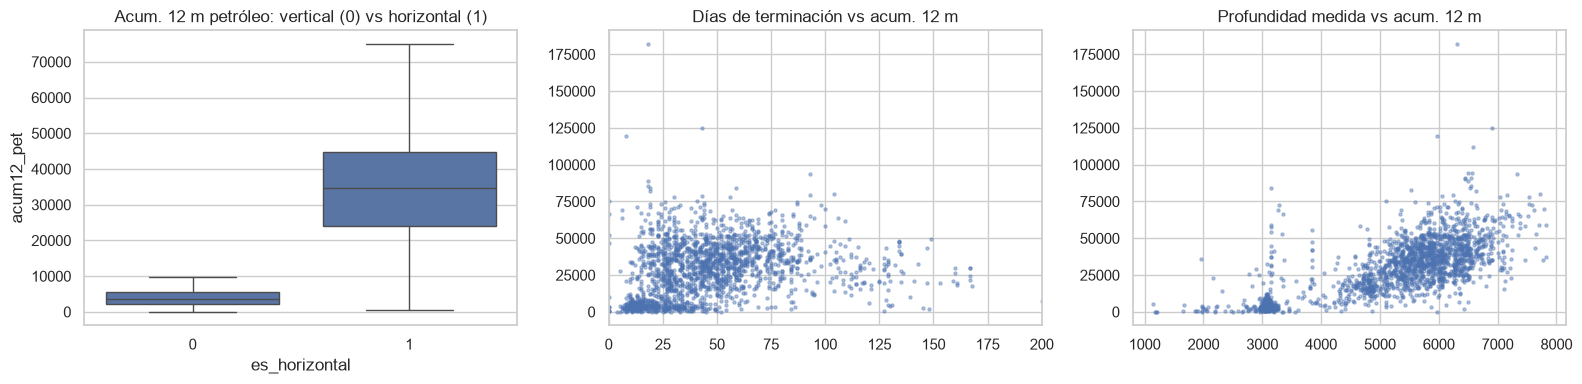

acum12_pet     1.000
dias_perf      0.386
dias_term      0.370
cota          -0.155
profundidad    0.734
anio_inicio    0.599
Name: acum12_pet, dtype: float64

In [6]:
print("Cobertura sobre los pozos de Neuquina:")
print(pozos.select(pl.col("cota", "dias_perf", "dias_term").is_not_null().mean()))
m12 = (panel.filter(pl.col("mes_produccion") <= 12).group_by("idpozo")
       .agg(acum12_pet=pl.col("prod_pet").sum(), n=pl.len()).filter(pl.col("n") == 12))
vm = (pozos.join(m12, on="idpozo")
      .filter((pl.col("formacion") == "vaca muerta") & (pl.col("tipopozo") == "Petrolífero")).to_pandas())
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=vm, x="es_horizontal", y="acum12_pet", ax=ax[0], showfliers=False); ax[0].set_title("Acum. 12 m petróleo: vertical (0) vs horizontal (1)")
ax[1].scatter(vm.dias_term, vm.acum12_pet, s=5, alpha=.4); ax[1].set_title("Días de terminación vs acum. 12 m"); ax[1].set_xlim(0, 200)
ax[2].scatter(vm.profundidad, vm.acum12_pet, s=5, alpha=.4); ax[2].set_title("Profundidad medida vs acum. 12 m")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_capitulo_iv.png", dpi=110); plt.show()
vm[["acum12_pet", "dias_perf", "dias_term", "cota", "profundidad", "anio_inicio"]].corr(method="spearman")["acum12_pet"].round(3)

Los pozos **horizontales** de Vaca Muerta producen ~10 veces más que los verticales en su primer año. Pero la **profundidad** ya captaba gran parte de ese efecto: en un pozo horizontal la profundidad informada es la *profundidad medida*, que incluye la rama lateral. Las duraciones de perforación y terminación correlacionan moderadamente (Spearman ≈ 0,37). En el entrenamiento se decide por **validación** si estas variables entran al modelo de pozo nuevo.

## Transformaciones (feature engineering)
Ver `src/ypf_ds/features/build.py`. Para cada pozo y mes de origen *t* se calculan, **solo con datos ≤ t**:
- `log1p` de petróleo, gas y agua del mes y lags 1, 2, 3, 6, 12; medias móviles 3 y 6.
- Pico histórico, producción/pico, acumulada, caudal por día efectivo, GOR, corte de agua, tendencia de 3 meses, meses desde el pico.
- Estáticas: formación, shale/tight, yacimiento, operadora (top 15 + OTRAS), profundidad, lat/lon, año de inicio.

**Encoding:** las categóricas se pasan como `category` nativo a LightGBM (sin one-hot: evita explotar 132 yacimientos en columnas). **Escalado:** no hace falta en árboles; sí se estandariza para Ridge, KNN, SVR y MLP en el notebook 03.

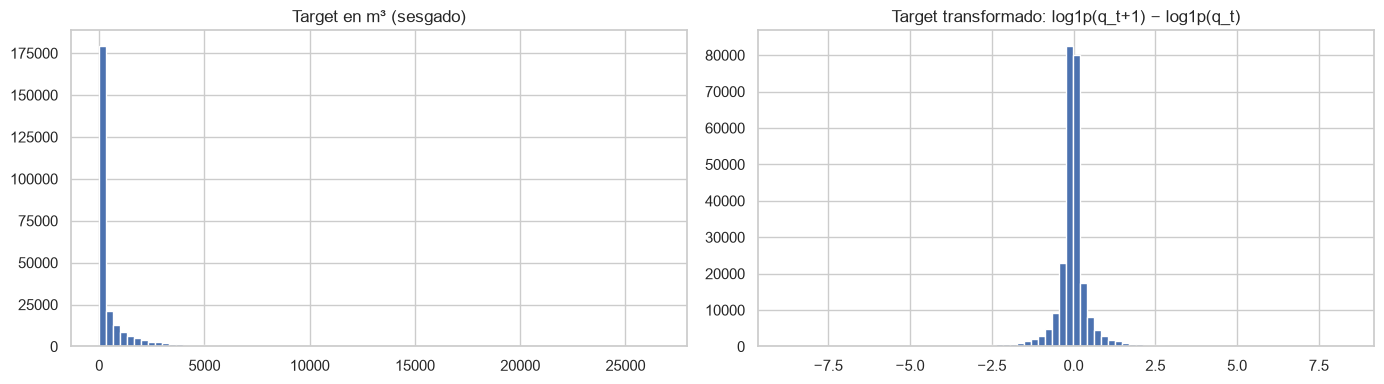

In [7]:
from ypf_ds.features import build as fb
dfa = fb.dataset_modo_a(panel, pozos, "petroleo", horizontes=[1])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(dfa["prod_obj"].to_numpy(), bins=80); ax[0].set_title("Target en m³ (sesgado)")
ax[1].hist(dfa["y"].to_numpy(), bins=80); ax[1].set_title("Target transformado: log1p(q_t+1) − log1p(q_t)")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_target.png", dpi=110); plt.show()

Modelar la **variación respecto del último mes** (en vez del nivel absoluto) deja el target centrado y hace que el modelo aprenda la *declinación*. En log queda casi simétrico; el modelo final usa el ratio `q[t+h]/q[t]` ponderado por volumen para no subestimar la media (ver notebook 03).